In [1]:
import os
import sys
from urllib.parse import quote_plus
from sqlalchemy import create_engine, text
import pandas as pd
import numpy as np
from scipy.stats import chisquare,fisher_exact
from scipy.stats import entropy
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from dotenv import load_dotenv
from pathlib import Path

Error: Failed to create kernel session on nbctl: nbctl vsessions unavailable: request to http://localhost:8888/api/internal/vsessions failed, reason: 

## Steps

- EDA
- Feature engineering (Creating features, Normalizing data, etc)
- Prediction : What players are have the highest probability to be selected for the 2026 world cup?

In [8]:
env_path = '../2 - Database/db.env'
load_dotenv(env_path, override=False)

# Variáveis de autenticação do banco de dados
DB_SERVER = os.getenv('DB_SERVER')
DB_PORT = os.getenv('DB_PORT','1433')  # Porta padrão do SQL Server
DB_NAME = os.getenv('DB_DATABASE')
DB_USER = os.getenv('DB_USER')
DB_PASSWORD = os.getenv('DB_PASSWORD')
ODBC_DRIVER = os.getenv('DB_DRIVER', 'ODBC Driver 17 for SQL Server')  # Driver ODBC padrão


# String de conexão
driver_q = quote_plus(ODBC_DRIVER)
base_params = f"driver={driver_q}&Encrypt=yes&TrustServerCertificate=yes"

# Função para criar a string de conexão
def conn_str(database: str) -> str:
    return (
        f"mssql+pyodbc://{quote_plus(DB_USER)}:{quote_plus(DB_PASSWORD)}@{DB_SERVER}:{DB_PORT}/{database}?"
        f"{base_params}"
    )

# Conecta ao banco
engine = create_engine(conn_str(DB_NAME), fast_executemany=True)

# Executa uma query SQL
try:
    with engine.connect() as connection:

        first_query = "SELECT  * FROM WCUP_HAS_TEAMS_TABLE "
        df = pd.read_sql_query(first_query, engine)

        print("\nDados de Quartis da tabela de Times exportado com sucesso !!!")

except Exception as e:
    print(f"Erro ao executar query: {e}")
finally:
    engine.dispose()
    print("\nConexão fechada.")


Dados de Quartis da tabela de Times exportado com sucesso !!!

Conexão fechada.


In [9]:
df.columns = ['YEAR', 'TEAM', 'TYPE','TOTAL','Q1','Q2','Q3','Q4']
df.head()

,YEAR,TEAM,TYPE,TOTAL,Q1,Q2,Q3,Q4
0,1930,Argentina,Frequence,22.0,10.0,6.0,1.0,5.0
1,1930,Argentina,Percentage(%),100.0,45.5,27.3,4.5,22.7
2,1930,Belgium,Frequence,16.0,3.0,6.0,4.0,3.0
3,1930,Belgium,Percentage(%),100.0,18.8,37.5,25.0,18.8
4,1930,Bolivia,Frequence,14.0,8.0,3.0,1.0,2.0


### Feature Engineering

Including Q1/Q4 may be more informative regarding how pronounced the relative age effect is in Q1.


In [10]:
df['Q1/Q4'] = df['Q4']/df['Q1']
df['Q1+Q2'] = df['Q1'] + df['Q2']
df['Q3+Q4'] = df['Q3'] + df['Q4']

In [11]:
df_frequence = df[df['TYPE'] == 'Frequence']
df_percentage = df[df['TYPE'] == 'Percentage(%)']

Adding chi-square as a feature

In [12]:
# Calcula o valor chi-square e p-value para a distribuição (Q1, Q2, Q3, Q4)

def calculate_chi_square(row):
    # Valores observados (já são frequências absolutas em df_frequence)
    observed = np.array([row['Q1'], row['Q2'], row['Q3'], row['Q4']])
    total_observed = observed.sum()
    
    if total_observed == 0:  
        return pd.Series([0, 1])  # chi2=0, p_value=1 (sem significância)
    
    
    # Frequências esperadas que somam exatamente o total observado
    expected = total_observed/4 * np.ones(4)  # Distribuição uniforme esperada

    # Retorna a estatística chi-square e o p-value
    chi2, p_value = chisquare(f_obs=observed, f_exp=expected)
    return pd.Series([chi2, p_value])



def calculate_odds_ratio(row):
    obs_first = row['Q1+Q2']
    obs_second = row['Q3+Q4']
    
    if obs_second == 0:
        return np.nan
    
  
    prop_first = 0.5
    prop_second = 0.5
    
    odds_obs = obs_first / obs_second
    odds_exp = prop_first / prop_second
    
    OR = odds_obs / odds_exp
    
    return OR


df_frequence[['chi_square', 'p_value']] = df_frequence.apply(calculate_chi_square, axis=1)
df_frequence['p_value'] = np.around(df_frequence['p_value'], 3)
df_frequence['Imbalanced (chi-square)'] = [1 if x < 0.05 else 0 for x in df_frequence['p_value']]

df_frequence['odds_ratio'] = df_frequence.apply(calculate_odds_ratio, axis=1)
df_frequence['Imbalanced (odds_ratio)'] = [1 if x > 1 else 0 for x in df_frequence['odds_ratio']]

# Mapeia as colunas chi_square, p_value e Imbalanced Dist para df_percentage
df_percentage = df_percentage.merge(
    df_frequence[['YEAR', 'TEAM', 'chi_square', 'p_value', 'Imbalanced (chi-square)','odds_ratio','Imbalanced (odds_ratio)']], 
    on=['YEAR', 'TEAM'], 
    how='left'
)


C:\Users\italo\AppData\Local\Temp\ipykernel_24372\916075888.py:40: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_frequence[['chi_square', 'p_value']] = df_frequence.apply(calculate_chi_square, axis=1)
C:\Users\italo\AppData\Local\Temp\ipykernel_24372\916075888.py:40: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_frequence[['chi_square', 'p_value']] = df_frequence.apply(calculate_chi_square, axis=1)
C:\Users\italo\AppData\Local\Temp\ipykernel_24372\916075888.py:41: SettingWithCopyWarning: 
A value is t

In [13]:
df_percentage.drop_duplicates(subset=['YEAR', 'TEAM'], inplace=True)

In [14]:
counts  = df_percentage.groupby('TEAM').count()[['YEAR']]
counts.sort_values(by='YEAR', ascending=False).head()

,YEAR
TEAM,
Brazil,22
Germany,20
Argentina,18
Italy,18
Mexico,17


In [15]:
cols_to_mean = [
    'Q1', 'Q2', 'Q3', 'Q4',
    'Q1/Q4', 'Q1+Q2', 'Q3+Q4',
    'chi_square', 'p_value', 'odds_ratio'
]
cols_to_sum = [
    'Imbalanced (chi-square)', 'Imbalanced (odds_ratio)'
]

available_mean_cols = [c for c in cols_to_mean if c in df_percentage.columns]
available_sum_cols = [c for c in cols_to_sum if c in df_percentage.columns]

df_agg_mean = (
    df_percentage
    .groupby('TEAM', as_index=False)[available_mean_cols]
    .mean()
    .rename(columns={c: f'MEAN_{c}' for c in available_mean_cols})
)

df_agg_sum = (
    df_percentage
    .groupby('TEAM', as_index=False)[available_sum_cols]
    .sum()
    .rename(columns={c: f'Nº {c}' for c in available_sum_cols})
)

df_agg = df_agg_mean.merge(df_agg_sum, on='TEAM', how='left')

# Mapeia counts por TEAM (evita desalinhamento de índice)
df_agg['counts'] = df_agg['TEAM'].map(counts['YEAR']).fillna(0).astype(int)



In [16]:
df_percentage.head()

,YEAR,TEAM,TYPE,TOTAL,Q1,Q2,Q3,Q4,Q1/Q4,Q1+Q2,Q3+Q4,chi_square,p_value,Imbalanced (chi-square),odds_ratio,Imbalanced (odds_ratio)
0,1930,Argentina,Percentage(%),100.0,45.5,27.3,4.5,22.7,0.498901,72.8,27.2,7.454545,0.059,0,2.666667,1
1,1930,Belgium,Percentage(%),100.0,18.8,37.5,25.0,18.8,1.000000,56.3,43.8,1.500000,0.682,0,1.285714,1
2,1930,Bolivia,Percentage(%),100.0,57.1,21.4,7.1,14.3,0.250438,78.5,21.4,8.285714,0.040,1,3.666667,1
3,1930,Brazil,Percentage(%),100.0,20.0,36.0,20.0,24.0,1.200000,56.0,44.0,1.720000,0.632,0,1.272727,1
4,1930,Chile,Percentage(%),100.0,42.1,31.6,15.8,10.5,0.249406,73.7,26.3,4.789474,0.188,0,2.800000,1


In [17]:
df_agg.head()

,TEAM,MEAN_Q1,MEAN_Q2,MEAN_Q3,MEAN_Q4,MEAN_Q1/Q4,MEAN_Q1+Q2,MEAN_Q3+Q4,MEAN_chi_square,MEAN_p_value,MEAN_odds_ratio,Nº Imbalanced (chi-square),Nº Imbalanced (odds_ratio),counts
0,Algeria,40.100000,27.825000,12.200000,19.850000,0.532648,67.925000,32.050000,4.918972,0.301000,2.310417,0,4,4
1,Angola,26.100000,26.100000,13.000000,34.800000,1.333333,52.200000,47.800000,2.217391,0.529000,1.090909,0,1,1
2,Argentina,29.272222,28.033333,20.788889,21.883333,0.953507,57.305556,42.672222,3.930750,0.333833,1.636706,0,12,18
3,Australia,22.850000,19.850000,32.200000,25.066667,1.077840,42.700000,57.266667,2.922672,0.493667,0.774576,0,1,6
4,Austria,37.657143,18.185714,20.771429,23.357143,0.708703,55.842857,44.128571,5.324675,0.283143,1.466815,1,4,7


### World cups Analysis

#### EDA

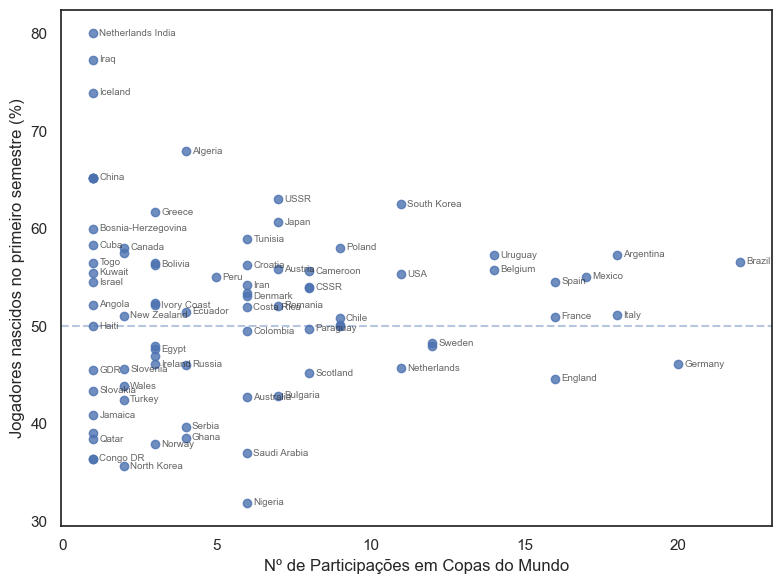

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="white")

df_agg_sorted = df_agg.sort_values('counts', ascending=True)
df_agg_filtered = df_agg_sorted[df_agg_sorted['MEAN_Q3+Q4'] <= 60]

fig, ax2 = plt.subplots(figsize=(8, 6))

# Chart único - Participações vs Q1+Q2
ax2.scatter(df_agg['counts'], df_agg['MEAN_Q1+Q2'], alpha=0.8)
ax2.axhline(y=50, color='C0', linestyle='--', linewidth=1.5, alpha=0.4)
ax2.set_xlabel("Nº de Participações em Copas do Mundo")
ax2.set_ylabel("Jogadores nascidos no primeiro semestre (%)")

labeled_points = []
min_distance = 1
for idx, row in df_agg.iterrows():
    x, y = row['counts'], row['MEAN_Q1+Q2']
    is_far_enough = True
    for lx, ly in labeled_points:
        distance = np.sqrt((x - lx)**2 + (y - ly)**2)
        if distance < min_distance:
            is_far_enough = False
            break
    if is_far_enough:
        ax2.text(x + 0.2, y, row['TEAM'], fontsize=7, ha='left', va='center', alpha=0.7)
        labeled_points.append((x, y))

plt.tight_layout()
plt.show()

#### Chi-square

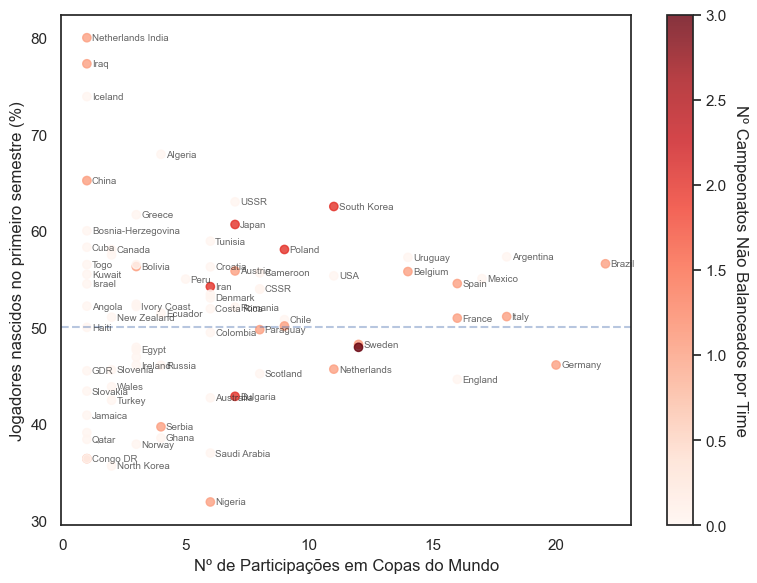

<Figure size 640x480 with 0 Axes>

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="white")

# Ordena por número de partidas (counts) para que países com mais partidas fiquem por cima
df_agg_sorted = df_agg.sort_values('counts', ascending=True)
#df_agg_sorted = df_agg_sorted[df_agg_sorted['Nº Imbalanced (chi-square)'] >= 1]
# Filtra apenas os pontos com MEAN_Q3+Q4 <= 60
df_agg_filtered = df_agg_sorted[df_agg_sorted['MEAN_Q3+Q4'] <= 60]

# Cria figura apenas para o gráfico do ax2
fig, ax2 = plt.subplots(figsize=(8, 6))

# Chart único - Counts vs Q1+Q2
scatter2 = ax2.scatter(df_agg['counts'], df_agg['MEAN_Q1+Q2'], 
                       c=df_agg['Nº Imbalanced (chi-square)'], cmap='Reds', alpha=0.8)
ax2.axhline(y=50, color='C0', linestyle='--', linewidth=1.5, alpha=0.4)
ax2.set_xlabel("Nº de Participações em Copas do Mundo")
ax2.set_ylabel("Jogadores nascidos no primeiro semestre (%)")

# Adiciona colorbar
cbar2 = plt.colorbar(scatter2, ax=ax2)
cbar2.set_label('Nº Campeonatos Não Balanceados por Time', rotation=270, labelpad=15)

# Adiciona labels
labeled_points = []
min_distance = 1

for idx, row in df_agg.iterrows():
    x, y = row['counts'], row['MEAN_Q1+Q2']
    
    is_far_enough = True
    for lx, ly in labeled_points:
        distance = np.sqrt((x - lx)**2 + (y - ly)**2)
        if distance < min_distance:
            is_far_enough = False
            break
    if is_far_enough:
        ax2.text(x + 0.2, y, row['TEAM'], fontsize=7, ha='left', va='center', alpha=0.7)
        labeled_points.append((x, y))

plt.tight_layout()
plt.show()
plt.savefig('Chi-square.svg',format = 'svg',bbox_inches='tight')

#### Odds Ratio

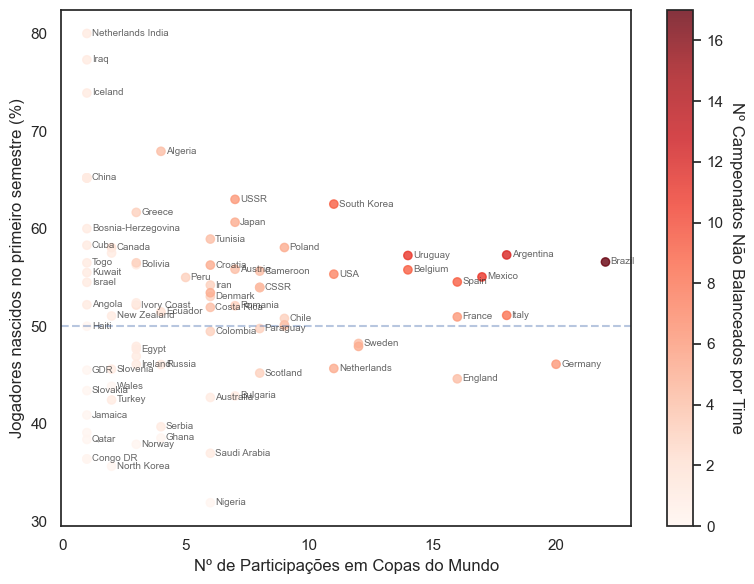

<Figure size 640x480 with 0 Axes>

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="white")

df_agg_sorted = df_agg.sort_values('counts', ascending=True)

# Filtra apenas os pontos com MEAN_Q3+Q4 <= 60
df_agg_filtered = df_agg_sorted[df_agg_sorted['MEAN_Q3+Q4'] <= 60]

# Cria figura apenas para o gráfico do ax2
fig, ax2 = plt.subplots(figsize=(8, 6))

# Chart único - Counts vs Q1+Q2
scatter2 = ax2.scatter(df_agg['counts'], df_agg['MEAN_Q1+Q2'], 
                       c=df_agg['Nº Imbalanced (odds_ratio)'], cmap='Reds', alpha=0.8)
ax2.axhline(y=50, color='C0', linestyle='--', linewidth=1.5, alpha=0.4)
ax2.set_xlabel("Nº de Participações em Copas do Mundo")
ax2.set_ylabel("Jogadores nascidos no primeiro semestre (%)")

# Adiciona colorbar
cbar2 = plt.colorbar(scatter2, ax=ax2)
cbar2.set_label('Nº Campeonatos Não Balanceados por Time', rotation=270, labelpad=15)

# Adiciona labels
labeled_points = []
min_distance = 1

for idx, row in df_agg.iterrows():
    x, y = row['counts'], row['MEAN_Q1+Q2']
    is_far_enough = True
    for lx, ly in labeled_points:
        distance = np.sqrt((x - lx)**2 + (y - ly)**2)
        if distance < min_distance:
            is_far_enough = False
            break
    
    if is_far_enough:
        ax2.text(x + 0.2, y, row['TEAM'], fontsize=7, ha='left', va='center', alpha=0.7)
        labeled_points.append((x, y))

plt.tight_layout()
plt.show()
plt.savefig('Odds Ratio.svg',format = 'svg')

In [21]:
df_agg[['TEAM','counts','MEAN_Q1+Q2','MEAN_Q3+Q4','Nº Imbalanced (chi-square)','Nº Imbalanced (odds_ratio)']].sort_values(by = 'counts',ascending = False).head(10)

,TEAM,counts,MEAN_Q1+Q2,MEAN_Q3+Q4,Nº Imbalanced (chi-square),Nº Imbalanced (odds_ratio)
8,Brazil,22,56.586364,43.400000,1,17
28,Germany,20,46.105000,53.905000,1,6
2,Argentina,18,57.305556,42.672222,0,12
39,Italy,18,51.116667,48.844444,1,8
44,Mexico,17,55.052941,44.917647,0,11
26,France,16,50.956250,49.025000,1,6
25,England,16,44.612500,55.356250,0,4
69,Spain,16,54.537500,45.450000,1,9
5,Belgium,14,55.778571,44.221429,1,9
80,Uruguay,14,57.250000,42.721429,0,11


In [22]:
df_agg[['TEAM','counts','MEAN_Q1+Q2','MEAN_Q3+Q4','Nº Imbalanced (chi-square)','Nº Imbalanced (odds_ratio)']].sort_values(by = 'Nº Imbalanced (odds_ratio)',ascending = False).head(10)

,TEAM,counts,MEAN_Q1+Q2,MEAN_Q3+Q4,Nº Imbalanced (chi-square),Nº Imbalanced (odds_ratio)
8,Brazil,22,56.586364,43.400000,1,17
2,Argentina,18,57.305556,42.672222,0,12
80,Uruguay,14,57.250000,42.721429,0,11
44,Mexico,17,55.052941,44.917647,0,11
69,Spain,16,54.537500,45.450000,1,9
68,South Korea,11,62.518182,37.490909,2,9
5,Belgium,14,55.778571,44.221429,1,9
39,Italy,18,51.116667,48.844444,1,8
77,USA,11,55.336364,44.636364,0,7
28,Germany,20,46.105000,53.905000,1,6


In [23]:
#df_agg['Percentual_teste'] = (df_agg['Nº Imbalanced (odds_ratio)'] / df_agg['counts']) * 100
#df_agg[['TEAM','counts','Nº Imbalanced (chi-square)','Nº Imbalanced (odds_ratio)','Percentual_teste']].sort_values(by = 'counts',ascending = False).head(10)


In [24]:
df_agg[['TEAM','counts','MEAN_Q1+Q2','MEAN_Q3+Q4','Nº Imbalanced (chi-square)','Nº Imbalanced (odds_ratio)']].sort_values(by = 'Nº Imbalanced (chi-square)',ascending = False).head(10)

,TEAM,counts,MEAN_Q1+Q2,MEAN_Q3+Q4,Nº Imbalanced (chi-square),Nº Imbalanced (odds_ratio)
71,Switzerland,12,47.933333,52.066667,3,5
35,Iran,6,54.216667,45.750000,2,3
42,Japan,7,60.657143,39.300000,2,5
68,South Korea,11,62.518182,37.490909,2,9
56,Poland,9,58.066667,41.911111,2,5
9,Bulgaria,7,42.857143,57.142857,2,1
26,France,16,50.956250,49.025000,1,6
69,Spain,16,54.537500,45.450000,1,9
49,Nigeria,6,31.916667,68.050000,1,0
64,Serbia,4,39.700000,60.300000,1,1


### PLAYERS

In [78]:
df_wcups = pd.read_csv('historico_jogadores.csv')
df_wcups.drop(columns = ['AGE_TODAY'], inplace=True)
df_wcups.head()


,ID,NAME,BIRTH_DAY,BIRTH_MONTH,BIRTH_YEAR,POSITION,GAME_YEAR,TEAMS_NAME,AGE
0,117,Ángel Bossio,5,5,1905,Goalkeeper,1930,Argentina,25
1,637,Arnold Badjou,25,6,1909,Goalkeeper,1930,Belgium,21
2,866,Jesus Bermúdez,24,1,1902,Goalkeeper,1930,Bolivia,28
3,1083,Joël,1,5,1904,Goalkeeper,1930,Brazil,26
4,1702,Roberto Cortés,2,2,1905,Goalkeeper,1930,Chile,25


In [79]:
df_wcups['LAST_AGE'] = df_wcups.groupby('NAME')['AGE'].transform('max')

In [80]:
df_wcups[df_wcups['NAME'] == 'Cristiano Ronaldo']

,ID,NAME,BIRTH_DAY,BIRTH_MONTH,BIRTH_YEAR,POSITION,GAME_YEAR,TEAMS_NAME,AGE,LAST_AGE
7792,5786,Cristiano Ronaldo,5,2,1985,Forward,2006,Portugal,21,37
8529,5786,Cristiano Ronaldo,5,2,1985,Forward,2010,Portugal,25,37
9205,5786,Cristiano Ronaldo,5,2,1985,Forward,2014,Portugal,29,37
10035,5786,Cristiano Ronaldo,5,2,1985,Forward,2018,Portugal,33,37
10834,5786,Cristiano Ronaldo,5,2,1985,Forward,2022,Portugal,37,37


#### EDA

In [81]:
# Agrupa por nome do jogador e time, contando quantas vezes cada jogador participou em cada edição da Copa do Mundo
players_wcups = df_wcups.groupby(['NAME', 'TEAMS_NAME'])['POSITION'].count().sort_values(ascending=False)
players_wcups.head(10)

NAME               TEAMS_NAME
Rafael Márquez     Mexico        5
Lothar Matthäus    Germany       5
Antonio Carbajal   Mexico        5
Gianluigi Buffon   Italy         5
Guillermo Ochoa    Mexico        5
Cristiano Ronaldo  Portugal      5
Andrés Guardado    Mexico        5
Lionel Messi       Argentina     5
Gilmar             Brazil        4
Iker Casillas      Spain         4
Name: POSITION, dtype: int64

In [82]:
# Cria um DataFrame para os jogadores, removendo duplicatas e mantendo apenas as colunas relevantes
df_plys = df_wcups.copy()
df_plys.drop_duplicates(['NAME', 'TEAMS_NAME'], inplace=True)
df_plys.set_index(['NAME', 'TEAMS_NAME'], inplace=True)
df_plys['matches'] = players_wcups
df_plys = df_plys[['POSITION','BIRTH_MONTH','LAST_AGE','matches']]
df_plys.sort_values(by='matches', ascending=False).head(10)

,,POSITION,BIRTH_MONTH,LAST_AGE,matches
NAME,TEAMS_NAME,,,,
Lionel Messi,Argentina,Forward,6,35,5
Andrés Guardado,Mexico,Midfielder,9,36,5
Guillermo Ochoa,Mexico,Goalkeeper,7,37,5
Rafael Márquez,Mexico,Defender,2,39,5
Antonio Carbajal,Mexico,Goalkeeper,6,37,5
Cristiano Ronaldo,Portugal,Forward,2,37,5
Lothar Matthäus,Germany,Midfielder,3,37,5
Gianluigi Buffon,Italy,Goalkeeper,1,36,5
Jacques Songo'o,Cameroon,Goalkeeper,3,38,4


In [83]:
# Filtrar jogadores com >= 4 partidas usando df_plys já calculado
df_pos = df_plys[df_plys['matches'] >= 4].copy()

# Mapear meses para trimestres
quarter_map = {
    1: 'Q1 (Jan-Mar)', 2: 'Q1 (Jan-Mar)', 3: 'Q1 (Jan-Mar)',
    4: 'Q2 (Abr-Jun)', 5: 'Q2 (Abr-Jun)', 6: 'Q2 (Abr-Jun)',
    7: 'Q3 (Jul-Set)', 8: 'Q3 (Jul-Set)', 9: 'Q3 (Jul-Set)',
    10: 'Q4 (Out-Dez)', 11: 'Q4 (Out-Dez)', 12: 'Q4 (Out-Dez)'
}
df_pos['QUARTER'] = df_pos['BIRTH_MONTH'].map(quarter_map)

# Crosstab: proporção de cada posição por trimestre (%)
position_by_quarter = pd.crosstab(df_pos['QUARTER'], df_pos['POSITION'], normalize='index') * 100
position_by_quarter = position_by_quarter.round(1)
position_by_quarter.index.name = 'Trimestre'
position_by_quarter

POSITION,Defender,Forward,Goalkeeper,Midfielder
Trimestre,,,,
Q1 (Jan-Mar),38.5,19.2,23.1,19.2
Q2 (Abr-Jun),35.0,10.0,30.0,25.0
Q3 (Jul-Set),26.1,21.7,30.4,21.7
Q4 (Out-Dez),11.8,11.8,35.3,41.2


In [84]:
# Percentual de jogadores (matches >= 4) nascidos em cada trimestre
quarter_dist = df_pos['QUARTER'].value_counts(normalize=True).sort_index() * 100
quarter_dist = quarter_dist.round(1).rename('% Jogadores')
quarter_dist.index.name = 'Trimestre'
quarter_dist.to_frame()

,% Jogadores
Trimestre,
Q1 (Jan-Mar),30.2
Q2 (Abr-Jun),23.3
Q3 (Jul-Set),26.7
Q4 (Out-Dez),19.8


#### DATA CLEANING

In [85]:
# Avaliando a quantidade de jogadores com mês de nascimento desconhecido (BIRTH_MONTH == 0) por time e ano
df_wcups[df_wcups['BIRTH_MONTH'] == 0][['TEAMS_NAME','GAME_YEAR']].value_counts().iloc[:5]

TEAMS_NAME         GAME_YEAR
Netherlands India  1938         14
Paraguay           1950          8
Morocco            1970          8
Paraguay           1930          6
Argentina          1934          4
Name: count, dtype: int64

In [86]:
# Avaliando quantos por cento de times tem até 5 jogadores com mês de nascimento desconhecido (BIRTH_MONTH == 0)
counts = df_wcups[df_wcups['BIRTH_MONTH'] == 0][['TEAMS_NAME','GAME_YEAR']].value_counts()
pd.qcut(counts, q=4, duplicates='drop').value_counts().sort_index()


count
(0.999, 2.0]    21
(2.0, 3.0]       4
(3.0, 14.0]      7
Name: count, dtype: int64

In [87]:
def filter_teams_with_unknown_birth_month(df, threshold=5):
    """
    - Times com MAIS de `threshold` jogadores com BIRTH_MONTH = 0 naquela copa → excluídos.
    - Times com ATÉ `threshold` jogadores com BIRTH_MONTH = 0 naquela copa → impute pela mediana
      de BIRTH_MONTH dos demais jogadores do mesmo time/ano.
    Retorna: (df_filtrado, df_imputados)
    """
    invalid_counts = (
        df[df['BIRTH_MONTH'] == 0]
        .groupby(['GAME_YEAR', 'TEAMS_NAME'])
        .size()
        .reset_index(name='invalid_count')
    )

    # --- Exclusão: > threshold ---
    teams_to_exclude = invalid_counts[invalid_counts['invalid_count'] > threshold][['GAME_YEAR', 'TEAMS_NAME']]
    mask_exclude = df.merge(teams_to_exclude, on=['GAME_YEAR', 'TEAMS_NAME'], how='left', indicator=True)['_merge'] == 'both'
    df_filtered = df[~mask_exclude.values].copy()

    excluded = len(teams_to_exclude)
    print(f"Times/edições excluídos (> {threshold} BIRTH_MONTH=0): {excluded}")

    # --- Impute: <= threshold ---
    # Mediana de BIRTH_MONTH por GAME_YEAR/TEAMS_NAME, considerando apenas valores válidos
    global_median = int(df_filtered[df_filtered['BIRTH_MONTH'] != 0]['BIRTH_MONTH'].median())

    median_by_team_year = (
        df_filtered[df_filtered['BIRTH_MONTH'] != 0]
        .groupby(['GAME_YEAR', 'TEAMS_NAME'])['BIRTH_MONTH']
        .median()
        .round()
        .astype(int)
    )

    teams_to_impute = invalid_counts[invalid_counts['invalid_count'] <= threshold][['GAME_YEAR', 'TEAMS_NAME']]
    mask_impute = (
        df_filtered.merge(teams_to_impute, on=['GAME_YEAR', 'TEAMS_NAME'], how='left', indicator=True)['_merge'] == 'both'
    ).values & (df_filtered['BIRTH_MONTH'] == 0).values

    # Salva os jogadores antes do impute para registro
    df_imputed_log = df_filtered.loc[mask_impute, ['NAME', 'TEAMS_NAME', 'GAME_YEAR', 'POSITION', 'BIRTH_MONTH']].copy()
    df_imputed_log.rename(columns={'BIRTH_MONTH': 'BIRTH_MONTH_ORIGINAL'}, inplace=True)

    imputed_values = (
        df_filtered.loc[mask_impute]
        .set_index(['GAME_YEAR', 'TEAMS_NAME'])
        .index
        .map(median_by_team_year)
    )
    # Fallback para global_median se algum time/ano não tiver nenhum valor válido
    imputed_values = pd.Series(imputed_values, index=df_filtered.loc[mask_impute].index).fillna(global_median).astype(int)

    df_filtered.loc[mask_impute, 'BIRTH_MONTH'] = imputed_values
    df_imputed_log['BIRTH_MONTH_IMPUTED'] = imputed_values.values

    imputed = int(mask_impute.sum())
    print(f"Jogadores com BIRTH_MONTH imputado (<= {threshold} por time/copa): {imputed}")
    print(f"BIRTH_MONTH = 0 restantes: {(df_filtered['BIRTH_MONTH'] == 0).sum()}")

    return df_filtered, df_imputed_log


df_wcups, df_imputed = filter_teams_with_unknown_birth_month(df_wcups)
print(f"\nTotal de linhas após limpeza: {len(df_wcups)}")


Times/edições excluídos (> 5 BIRTH_MONTH=0): 4
Jogadores com BIRTH_MONTH imputado (<= 5 por time/copa): 52
BIRTH_MONTH = 0 restantes: 0

Total de linhas após limpeza: 10890


In [88]:
print(f"A quantidade de jogadores que foram preenchidos com mediana é {df_imputed.drop_duplicates(subset=['NAME', 'TEAMS_NAME']).shape[0]}")

A quantidade de jogadores que foram preenchidos com mediana é 52


In [89]:
df_imputed.drop_duplicates(subset=['TEAMS_NAME','GAME_YEAR']).shape[0]

28

In [90]:
df_imputed.head()

,NAME,TEAMS_NAME,GAME_YEAR,POSITION,BIRTH_MONTH_ORIGINAL,BIRTH_MONTH_IMPUTED
28,José Chavarría,Bolivia,1930,Defender,0,3
51,Branislav Markovic,Yugoslavia,1930,Defender,0,8
102,Bill O'Brian,USA,1930,Midfielder,0,6
106,Constantino Noya,Bolivia,1930,Midfielder,0,3
112,Jose Flores,Peru,1930,Midfielder,0,6


#### Feature Engineering

In [91]:
# Número acumulado de Copas por jogador até cada edição
# rank do ano da copa dentro do grupo (ordenado cronologicamente)
df_wcups['ATTENDANCE'] = (
    df_wcups.groupby(['NAME', 'TEAMS_NAME'])['GAME_YEAR']
    .transform(lambda x: x.map({year: i+1 for i, year in enumerate(sorted(x.unique()))}))
)
df_wcups[['NAME', 'TEAMS_NAME', 'GAME_YEAR', 'ATTENDANCE']].sort_values(['NAME', 'TEAMS_NAME', 'GAME_YEAR']).head(20)

,NAME,TEAMS_NAME,GAME_YEAR,ATTENDANCE
8429,Aaron Clapham,New Zealand,2010,1
5801,Aaron Lawrence,Jamaica,1998,1
7780,Aaron Lennon,England,2006,1
8418,Aaron Lennon,England,2010,2
10332,Aaron Long,USA,2022,1
6675,Aaron Mokoena,South Africa,2002,1
8181,Aaron Mokoena,South Africa,2010,2
9887,Aaron Mooy,Australia,2018,1
10687,Aaron Mooy,Australia,2022,2
10216,Aaron Ramsdale,England,2022,1


In [132]:
# Anos de Copa em ordem crescente
wcup_years = sorted(df_wcups['GAME_YEAR'].unique())
next_year_map = {year: wcup_years[i+1] for i, year in enumerate(wcup_years[:-1])}

# Conjunto de (NAME, TEAMS_NAME, GAME_YEAR) para lookup rápido
present_set = set(zip(df_wcups['NAME'], df_wcups['TEAMS_NAME'], df_wcups['GAME_YEAR']))

def label_next_cup(row):
    next_year = next_year_map.get(row['GAME_YEAR'])
    if next_year is None:
        return 0  # última copa, não há próxima
    return int((row['NAME'], row['TEAMS_NAME'], next_year) in present_set)

df_wcups['LABEL'] = df_wcups.apply(label_next_cup, axis=1)

# Verificar com Pele
df_wcups[df_wcups['NAME'] == 'Pelé'][['NAME', 'TEAMS_NAME', 'GAME_YEAR', 'ATTENDANCE', 'LABEL']]

,NAME,TEAMS_NAME,GAME_YEAR,ATTENDANCE,LABEL
60491,Pelé,Brazil,1958,1,1
60492,Pelé,Brazil,1962,2,1
60493,Pelé,Brazil,1966,3,1
60494,Pelé,Brazil,1970,4,1
60495,Pelé,Brazil,1974,4,1
60496,Pelé,Brazil,1978,4,1
60497,Pelé,Brazil,1982,4,1
60498,Pelé,Brazil,1986,4,1
60499,Pelé,Brazil,1990,4,1
60500,Pelé,Brazil,1994,4,1


In [133]:
df_wcups[['GAME_YEAR','TEAMS_NAME','NAME','BIRTH_MONTH','AGE','LABEL']].iloc[20:30]

,GAME_YEAR,TEAMS_NAME,NAME,BIRTH_MONTH,AGE,LABEL
20,2018,South Africa,Aaron Mokoena,11,38,1
21,2022,South Africa,Aaron Mokoena,11,42,0
22,2018,Australia,Aaron Mooy,9,28,1
23,2022,Australia,Aaron Mooy,9,32,0
24,2022,England,Aaron Ramsdale,5,24,0
25,2022,Wales,Aaron Ramsey,12,32,0
26,1966,Mexico,Aarón Padilla,7,24,1
27,1970,Mexico,Aarón Padilla,7,28,1
28,1974,Mexico,Aarón Padilla,7,32,1
29,1978,Mexico,Aarón Padilla,7,36,1


In [134]:
# Pegar informações estáticas de cada jogador pela última linha registrada
player_info = (
    df_wcups.sort_values('GAME_YEAR')
    .drop_duplicates(['NAME', 'TEAMS_NAME'], keep='last')
    .set_index(['NAME', 'TEAMS_NAME'])
)

# Último ano de copa por jogador
last_year_per_player = df_wcups.groupby(['NAME', 'TEAMS_NAME'])['GAME_YEAR'].max()

new_rows = []
for (name, team), last_year in last_year_per_player.items():
    future_years = [y for y in wcup_years if y > last_year]
    if not future_years:
        continue

    info = player_info.loc[(name, team)]
    for year in future_years:
        new_rows.append({
            'ID': None,
            'NAME': name,
            'BIRTH_DAY': info['BIRTH_DAY'],
            'BIRTH_MONTH': info['BIRTH_MONTH'],
            'BIRTH_YEAR': info['BIRTH_YEAR'],
            'POSITION': info['POSITION'],
            'GAME_YEAR': year,
            'TEAMS_NAME': team,
            'AGE': year - info['BIRTH_YEAR'],
            'LAST_AGE': info['LAST_AGE'],
            'ATTENDANCE': info['ATTENDANCE'],  # não incrementa, pois não participou
            'LABEL': 0
        })

df_missing = pd.DataFrame(new_rows)
df_wcups_real = df_wcups.copy()
df_wcups = pd.concat([df_wcups, df_missing], ignore_index=True).sort_values(['NAME', 'TEAMS_NAME', 'GAME_YEAR']).reset_index(drop=True)

print(f'Linhas originais: {len(df_wcups) - len(df_missing)} | Linhas adicionadas: {len(df_missing)} | Total: {len(df_wcups)}')

# Verificar com Pelé

Linhas originais: 80636 | Linhas adicionadas: 0 | Total: 80636


In [135]:
df_wcups[df_wcups['NAME'] == 'Pelé'][['NAME', 'TEAMS_NAME', 'BIRTH_MONTH','GAME_YEAR', 'AGE','LAST_AGE', 'ATTENDANCE', 'LABEL']].head(10)

,NAME,TEAMS_NAME,BIRTH_MONTH,GAME_YEAR,AGE,LAST_AGE,ATTENDANCE,LABEL
60491,Pelé,Brazil,10,1958,18,30,1,1
60492,Pelé,Brazil,10,1962,22,30,2,1
60493,Pelé,Brazil,10,1966,26,30,3,1
60494,Pelé,Brazil,10,1970,30,30,4,1
60495,Pelé,Brazil,10,1974,34,30,4,1
60496,Pelé,Brazil,10,1978,38,30,4,1
60497,Pelé,Brazil,10,1982,42,30,4,1
60498,Pelé,Brazil,10,1986,46,30,4,1
60499,Pelé,Brazil,10,1990,50,30,4,1
60500,Pelé,Brazil,10,1994,54,30,4,1


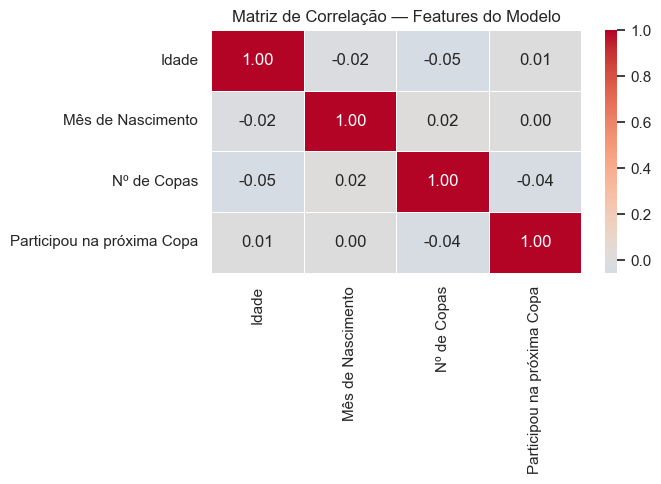

In [136]:
import matplotlib.pyplot as plt
import seaborn as sns

corr_cols = ['AGE', 'BIRTH_MONTH', 'ATTENDANCE', 'LABEL']
label_map = {
    'AGE':         'Idade',
    'BIRTH_MONTH': 'Mês de Nascimento',
    'ATTENDANCE':  'Nº de Copas',
    'LABEL':       'Participou na próxima Copa',
}

corr_matrix = df_wcups[corr_cols].corr()
corr_matrix_pt = corr_matrix.rename(index=label_map, columns=label_map)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(
    corr_matrix_pt,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5,
    ax=ax
)
ax.set_title('Matriz de Correlação — Features do Modelo')
plt.tight_layout()
plt.show()


## Binary Classifier

In [137]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score
from imblearn.over_sampling import SMOTE

# Treinar apenas com copas históricas onde o LABEL da próxima edição é conhecido.
# Excluir 2022: o verdadeiro rótulo (participou em 2026?) ainda é desconhecido.
df_train = df_wcups[df_wcups['GAME_YEAR'] < 2022].copy()

# Encoding de POSITION
le_pos = LabelEncoder()
df_train['POSITION_ENC'] = le_pos.fit_transform(df_train['POSITION'])

features = ['AGE', 'BIRTH_MONTH', 'POSITION_ENC']
X = df_train[features]
y = df_train['LABEL']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Aplica SMOTE para balancear as classes no conjunto de treino
sm = SMOTE(random_state=42)
X_train, y_train = sm.fit_resample(X_train, y_train)


### Baseline Classifier

In [138]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy='stratified', random_state=42)
baseline.fit(X_train, y_train)
print(baseline.score(X_test, y_test))

0.5069535736525289


### Logistic Regression

In [139]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(max_iter=500, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)


In [140]:
# Candidatos à Copa de 2026: jogadores que participaram da Copa de 2022 (linhas reais)
df_2026 = df_wcups[(df_wcups['GAME_YEAR'] == 2022) & (df_wcups['ID'].notna())].copy()
df_2026['POSITION_ENC'] = le_pos.transform(df_2026['POSITION'])

# Idade projetada para 2026
df_2026['AGE_2026'] = 2026 - df_2026['BIRTH_YEAR']

X_2026 = df_2026[['AGE_2026', 'BIRTH_MONTH', 'POSITION_ENC']].rename(columns={'AGE_2026': 'AGE'})
df_2026['PROB_2026'] = clf.predict_proba(X_2026)[:, 1]

result = (
    df_2026[['NAME', 'TEAMS_NAME', 'POSITION', 'BIRTH_MONTH', 'AGE_2026', 'ATTENDANCE', 'PROB_2026']]
    .drop_duplicates(['NAME', 'TEAMS_NAME'])
    .sort_values('PROB_2026', ascending=False)
)
result.head(20)


,NAME,TEAMS_NAME,POSITION,BIRTH_MONTH,AGE_2026,ATTENDANCE,PROB_2026
14982,Danilo,Brazil,Defender,12,106,3,1.000000
66137,Rodri,Spain,Midfielder,3,92,2,1.000000
59197,Pape Sarr,Senegal,Midfielder,12,49,2,0.999926
3987,Ali Karimi,Iran,Midfielder,11,48,2,0.999881
55314,Moussa N'Diaye,Senegal,Defender,2,47,2,0.999645
3846,Alfredo Talavera,Mexico,Goalkeeper,9,44,3,0.999084
24049,Fred,Brazil,Midfielder,10,43,4,0.998799
7598,Atiba Hutchinson,Canada,Midfielder,2,43,1,0.998692
64037,Remko Pasveer,Netherlands,Goalkeeper,11,43,1,0.998579
18765,Eiji Kawashima,Japan,Goalkeeper,3,43,4,0.998452


### Random Forest

In [110]:
from sklearn.ensemble import RandomForestClassifier

clf_rf = RandomForestClassifier(n_estimators=300, random_state=42)
clf_rf.fit(X_train, y_train)
y_pred_rf = clf_rf.predict(X_test)


In [111]:
df_2026['PROB_2026_RF'] = clf_rf.predict_proba(X_2026)[:, 1]

result_rf = (
    df_2026[['NAME', 'TEAMS_NAME', 'POSITION', 'BIRTH_MONTH', 'AGE_2026', 'ATTENDANCE', 'PROB_2026_RF']]
    .drop_duplicates(['NAME', 'TEAMS_NAME'])
    .sort_values('PROB_2026_RF', ascending=False)
)
result_rf.head(20)


,NAME,TEAMS_NAME,POSITION,BIRTH_MONTH,AGE_2026,ATTENDANCE,PROB_2026_RF
382,Abdul Issahaku,Ghana,Midfielder,3,22,1,0.987454
70322,Simon Ngapandouetnbu,Cameroon,Goalkeeper,4,23,1,0.986637
10335,Brandon Aguilera,Costa Rica,Midfielder,6,23,1,0.974781
42329,Jude Bellingham,England,Midfielder,6,23,1,0.974781
57400,Nuno Mendes,Portugal,Defender,6,24,1,0.972859
78510,Xavi Simons,Netherlands,Midfielder,4,23,1,0.972798
77642,William Saliba,France,Defender,3,25,1,0.966259
32589,Ibrahim Danlad,Ghana,Goalkeeper,12,24,1,0.961504
74762,Unai Simón,Spain,Goalkeeper,6,29,1,0.960780
56083,Neco Williams,Wales,Defender,4,25,1,0.957710


### XGBoost

In [112]:
from xgboost import XGBClassifier

clf_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss',
    use_label_encoder=False
)
clf_xgb.fit(X_train, y_train)
y_pred_xgb = clf_xgb.predict(X_test)


c:\Users\italo\AppData\Local\Programs\Python\Python311\Lib\site-packages\xgboost\training.py:200: UserWarning: [07:11:30] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [113]:
df_2026['PROB_2026_XGB'] = clf_xgb.predict_proba(X_2026)[:, 1]

result_xgb = (
    df_2026[['NAME', 'TEAMS_NAME', 'POSITION', 'BIRTH_MONTH', 'AGE_2026', 'ATTENDANCE', 'PROB_2026_XGB']]
    .drop_duplicates(['NAME', 'TEAMS_NAME'])
    .sort_values('PROB_2026_XGB', ascending=False)
)
result_xgb.head(20)


,NAME,TEAMS_NAME,POSITION,BIRTH_MONTH,AGE_2026,ATTENDANCE,PROB_2026_XGB
382,Abdul Issahaku,Ghana,Midfielder,3,22,1,0.957507
10335,Brandon Aguilera,Costa Rica,Midfielder,6,23,1,0.955821
42329,Jude Bellingham,England,Midfielder,6,23,1,0.955821
70322,Simon Ngapandouetnbu,Cameroon,Goalkeeper,4,23,1,0.954228
78510,Xavi Simons,Netherlands,Midfielder,4,23,1,0.953440
24919,Gavi,Spain,Midfielder,8,22,1,0.948455
37301,Jewison Bennette,Costa Rica,Midfielder,6,22,1,0.942661
6779,Ardon Jashari,Switzerland,Midfielder,7,24,1,0.942362
29336,Hannibal,Tunisia,Midfielder,1,23,1,0.940875
71619,Strahinja Pavlovic,Serbia,Defender,5,25,1,0.938778


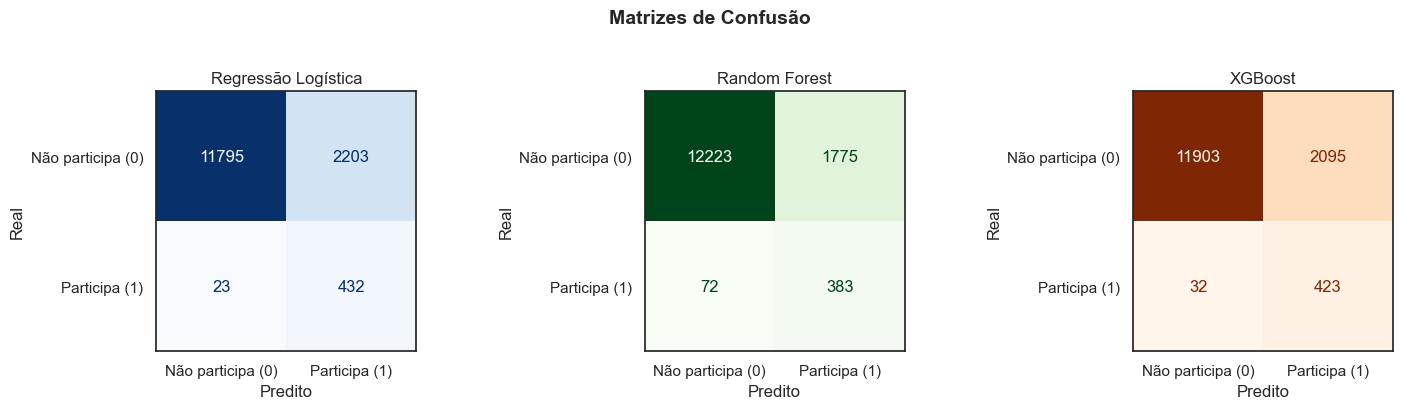

In [114]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

labels = ['Não participa (0)', 'Participa (1)']
configs = [
    (y_pred,     'Regressão Logística', 'Blues'),
    (y_pred_rf,  'Random Forest',       'Greens'),
    (y_pred_xgb, 'XGBoost',             'Oranges'),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (preds, title, cmap) in zip(axes, configs):
    cm = confusion_matrix(y_test, preds)
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels).plot(
        cmap=cmap, ax=ax, colorbar=False
    )
    ax.set_title(title)
    ax.set_xlabel('Predito')
    ax.set_ylabel('Real')

plt.suptitle('Matrizes de Confusão', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


In [115]:
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, accuracy_score

models = {
    'Baseline' : (baseline, baseline.predict(X_test)),
    'Logistic Regression': (clf, y_pred),
    'Random Forest':       (clf_rf, y_pred_rf),
    'XGBoost':             (clf_xgb, y_pred_xgb),
}

rows = []
for model_name, (model, preds) in models.items():
    proba = model.predict_proba(X_test)[:, 1]
    for label, cls in [(0, 'Não Participou'), (1, 'Participou')]:
        mask = (y_test == label)
        rows.append({
            'Modelo':     model_name,
            'Classe':     cls,
            'Precision':  round(precision_score(y_test, preds, pos_label=label, zero_division=0), 4),
            'Recall':     round(recall_score(y_test, preds, pos_label=label, zero_division=0), 4),
            'F1-Score':   round(f1_score(y_test, preds, pos_label=label, zero_division=0), 4),
            'Support':    int(mask.sum()),
        })
    rows.append({
        'Modelo':     model_name,
        'Classe':     'ROC-AUC',
        'Precision':  '-',
        'Recall':     '-',
        'F1-Score':   '-',
        'Support':    round(roc_auc_score(y_test, proba), 4),
    })

df_metrics = pd.DataFrame(rows).set_index(['Modelo', 'Classe'])
df_metrics.style.set_caption('Métricas de Performance dos Modelos')


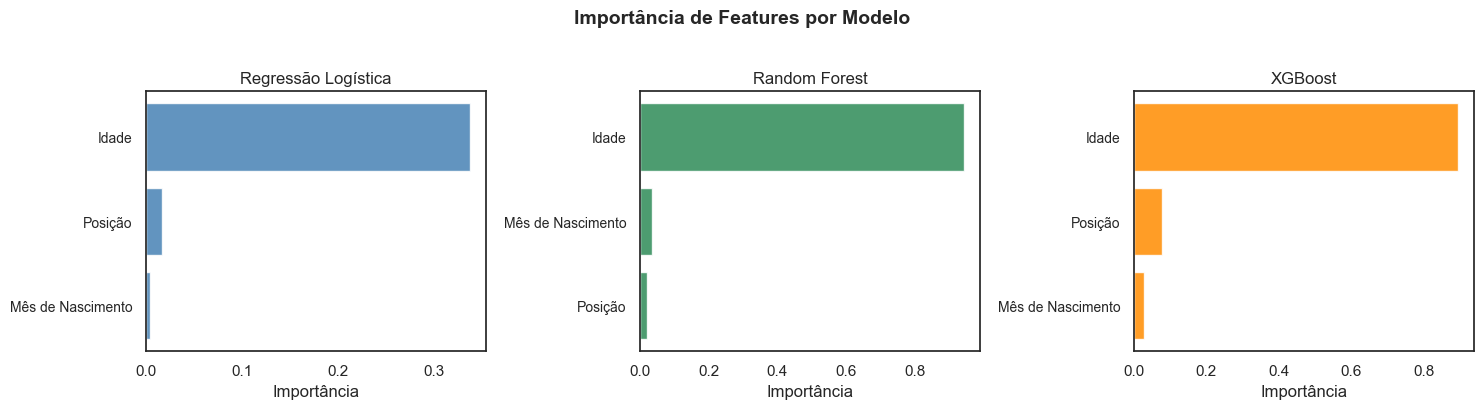

In [116]:
import matplotlib.pyplot as plt
import numpy as np

feature_label_map = {
    'AGE':          'Idade',
    'BIRTH_MONTH':  'Mês de Nascimento',
    'ATTENDANCE':   'Participações',
    'POSITION_ENC': 'Posição',
}
feature_names_pt = [feature_label_map[f] for f in features]

importances = {
    'Regressão Logística': np.abs(clf.coef_[0]),
    'Random Forest':       clf_rf.feature_importances_,
    'XGBoost':             clf_xgb.feature_importances_,
}
colors = ['steelblue', 'seagreen', 'darkorange']

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)

for ax, (model_name, imp), color in zip(axes, importances.items(), colors):
    order = np.argsort(imp)
    ax.barh(
        [feature_names_pt[i] for i in order],
        imp[order],
        color=color,
        alpha=0.85,
    )
    ax.set_title(model_name)
    ax.set_xlabel('Importância')
    ax.tick_params(axis='y', labelsize=10)

plt.suptitle('Importância de Features por Modelo', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


In [117]:
result[result['TEAMS_NAME'] == 'Brazil']

,NAME,TEAMS_NAME,POSITION,BIRTH_MONTH,AGE_2026,ATTENDANCE,PROB_2026
24649,Gabriel Martinelli,Brazil,Forward,6,25,1,9.007628e-01
66221,Rodrygo,Brazil,Forward,1,25,1,8.989031e-01
75852,Vinícius Júnior,Brazil,Forward,7,26,1,8.667611e-01
6479,Antony,Brazil,Forward,2,26,1,8.643602e-01
17986,Eder Militão,Brazil,Defender,1,28,1,7.668153e-01
10579,Bremer,Brazil,Defender,3,29,1,7.029597e-01
60134,Pedro,Brazil,Forward,6,29,1,7.019883e-01
64847,Richarlison,Brazil,Forward,5,29,1,7.011243e-01
24648,Gabriel Jesus,Brazil,Forward,4,29,2,7.002588e-01
10888,Bruno Guimarães,Brazil,Midfielder,11,29,1,6.991727e-01


In [118]:

# Mapear BIRTH_MONTH -> trimestre
quarter_map_xgb = {
    1: 'Q1', 2: 'Q1', 3: 'Q1',
    4: 'Q2', 5: 'Q2', 6: 'Q2',
    7: 'Q3', 8: 'Q3', 9: 'Q3',
    10: 'Q4', 11: 'Q4', 12: 'Q4'
}

_tmp = result_xgb.copy()
_tmp['QUARTER'] = _tmp['BIRTH_MONTH'].map(quarter_map_xgb)

# Contar jogadores por time e trimestre
df_xgb_freq = (
    _tmp.groupby('TEAMS_NAME')['QUARTER']
    .value_counts()
    .unstack(fill_value=0)
    .reset_index()
)

# Garantir que todas as colunas Q1-Q4 existam
for q in ['Q1', 'Q2', 'Q3', 'Q4']:
    if q not in df_xgb_freq.columns:
        df_xgb_freq[q] = 0

df_xgb_freq['Q1+Q2'] = df_xgb_freq['Q1'] + df_xgb_freq['Q2']
df_xgb_freq['Q3+Q4'] = df_xgb_freq['Q3'] + df_xgb_freq['Q4']

# Aplicar qui-quadrado e odds_ratio
df_xgb_freq[['chi_square', 'p_value']] = df_xgb_freq.apply(calculate_chi_square, axis=1)
df_xgb_freq['p_value'] = np.around(df_xgb_freq['p_value'], 3)
df_xgb_freq['Imbalanced (chi-square)'] = [1 if x < 0.05 else 0 for x in df_xgb_freq['p_value']]

df_xgb_freq['odds_ratio'] = df_xgb_freq.apply(calculate_odds_ratio, axis=1)
df_xgb_freq['Imbalanced (odds_ratio)'] = [1 if x > 1 else 0 for x in df_xgb_freq['odds_ratio']]




In [119]:
df_xgb_freq[['TEAMS_NAME', 'Q1+Q2', 'Q3+Q4',
             'chi_square', 'p_value', 'Imbalanced (chi-square)',
             'odds_ratio', 'Imbalanced (odds_ratio)']].sort_values(by='chi_square', ascending=False).head(10)

QUARTER,TEAMS_NAME,Q1+Q2,Q3+Q4,chi_square,p_value,Imbalanced (chi-square),odds_ratio,Imbalanced (odds_ratio)
19,Poland,20,6,8.769231,0.033,1,3.333333,1
25,South Korea,10,16,7.538462,0.057,0,0.625000,0
28,Tunisia,16,10,6.615385,0.085,0,1.600000,1
5,Canada,16,10,5.384615,0.146,0,1.600000,1
11,France,16,9,5.240000,0.155,0,1.777778,1
2,Belgium,18,8,5.076923,0.166,0,2.250000,1
29,USA,10,16,4.461538,0.216,0,0.625000,0
23,Senegal,16,10,4.461538,0.216,0,1.600000,1
26,Spain,15,11,4.461538,0.216,0,1.363636,1
14,Iran,16,9,4.280000,0.233,0,1.777778,1


In [120]:
df_xgb_freq[['TEAMS_NAME', 'Q1+Q2', 'Q3+Q4',
             
             'odds_ratio', 'Imbalanced (odds_ratio)']].sort_values(by='odds_ratio', ascending=False).head(10)

QUARTER,TEAMS_NAME,Q1+Q2,Q3+Q4,odds_ratio,Imbalanced (odds_ratio)
19,Poland,20,6,3.333333,1
0,Argentina,18,8,2.250000,1
2,Belgium,18,8,2.250000,1
6,Costa Rica,17,9,1.888889,1
30,Uruguay,17,9,1.888889,1
18,Netherlands,17,9,1.888889,1
11,France,16,9,1.777778,1
14,Iran,16,9,1.777778,1
28,Tunisia,16,10,1.600000,1
23,Senegal,16,10,1.600000,1
